# Estimasi Ketersediaan Pangan Kabupaten (NCPR) dengan FT-Transformer

Estimasi NCPR (Normative Consumption to Production Ratio) setiap kabupaten untuk FSVA edisi berikutnya menggunakan FT-Transformer, Transformer untuk data tabel. Model utama memakai seluruh 20 fitur; set 4 fitur diuji sebagai skenario.

Tujuan:

- Membangun FT-Transformer dengan 20 fitur untuk menebak perubahan NCPR setiap kabupaten, lalu mengujinya di FSVA 2026.
- Menjalankan skenario tambahan: seleksi fitur dan set 4 fitur.
- Meramal NCPR FSVA 2027 (kondisi 2026, forecasting) dengan data produksi 2026 yang baru tersedia sebagian.
- Mensimulasikan ramalan FSVA 2026 dari posisi pertengahan 2025 untuk mengukur ketepatan sistem dalam kondisi forecast.
- Menandai kabupaten yang berpeluang masuk atau keluar dari status defisit pangan.

Target: perubahan NCPR setiap kabupaten dari FSVA tahun ini ke FSVA tahun berikutnya, yang kemudian dikembalikan menjadi nilai NCPR. NCPR 1 atau lebih berarti produksi pangan kabupaten tidak mencukupi kebutuhan konsumsi normatif penduduknya (defisit), sedangkan NCPR di bawah 1 berarti surplus (Laporan FSVA Nasional 2025).

# Library

In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from matplotlib.lines import Line2D
from sklearn.preprocessing import StandardScaler
import json

In [2]:
SEED = 42

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
COLORS = {"utama": "#185FA5", "hijau": "#1D9E75", "oranye": "#D85A30", "abu": "#B4B2A9"}
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

# Data Understanding

Dataset: `dataset_gabungan_kabupaten.csv`

Gabungan beberapa sumber pada resolusi kabupaten/kota-tahun:

| Sumber | Isi | Tingkat |
|---|---|---|
| FSVA Bapanas metode lama (tabel 2018–2024) | 9 indikator ketahanan pangan, termasuk NCPR, dan skor IKP | kabupaten/kota |
| Peta FSVA Bapanas (fsva.badanpangan.go.id) | NCPR metode baru: FSVA 2024 yang dihitung ulang (backcasting), FSVA 2025, FSVA 2026 | kabupaten/kota |
| BDSP Kementan, WebAPI dan PDF publikasi BPS provinsi, Open Data Aceh | produksi padi tahunan | kabupaten/kota |
| BDSP Kementan | produksi jagung, ubi kayu, ubi jalar, sagu | kabupaten/kota |
| NASA POWER (MERRA-2) | curah hujan dan suhu | kabupaten/kota (sel grid) |
| PIHPS Bank Indonesia | harga beras medium | provinsi |
| BPS (KSA) | produksi padi dan luas panen | provinsi |
| NOAA CPC | indeks ONI (El Niño/La Niña) | nasional |

Cakupan: 514 kabupaten/kota, tahun 2018–2026, 4.626 baris, 36 kolom. Data diambil dengan skrip di folder `data_scraping_pipeline/` (nama kabupaten dari setiap sumber dicocokkan ke kode BPS di sana).

FSVA tahun t disusun dari data tahun t−1. Akibatnya, NCPR FSVA t+1 dihitung dari produksi tahun t, dan produksi tahun t sudah dirilis BPS sekitar Februari–Maret t+1. Aturan yang dipakai di seluruh notebook: fitur untuk menebak FSVA t+1 hanya memakai data yang sudah tersedia saat produksi tahun t dirilis.

| Data pada baris tahun t | Kondisi yang dipotret | Tersedia |
|---|---|---|
| Indikator FSVA t (termasuk NCPR) | tahun t−1 | saat FSVA t terbit |
| Produksi pangan kabupaten | Januari–Desember t | sekitar Februari–Maret t+1 |
| Curah hujan, suhu, harga, produksi provinsi, ONI | Agustus t−1 sampai Juli t | sekitar Agustus t |
| **Target: NCPR FSVA t+1** | tahun t | saat FSVA t+1 terbit, beberapa bulan kemudian |

Karena kondisi yang ditebak sudah terjadi dan yang dipercepat hanya angka resminya, pekerjaan ini disebut **nowcasting** (estimasi dini).

In [3]:
FILE_ID = "1EhvK2TzqFgi7LPltVFnXhiA8pOCLaMmv"   # id file dataset_gabungan_kabupaten.csv di Google Drive
url = f"https://drive.google.com/uc?export=download&id={FILE_ID}"
LOKAL = Path("../data/processed/dataset_gabungan_kabupaten.csv")   # ada kalau dijalankan dari repo (laptop / GitHub Actions)

data = pd.read_csv(LOKAL if LOKAL.exists() else url)
data.head(10)

,kode_bps,kab_kota,provinsi,wilayah_34,jenis,tahun,ncpr,miskin,pengeluaran_pangan,tanpa_listrik,tanpa_air,lama_sekolah_perempuan,rasio_nakes,ahh,stunting,ikp,ncpr_metode_baru,miskin_metode_baru,lama_sekolah_perempuan_metode_baru,tanpa_air_metode_baru,stunting_metode_baru,produksi_padi_utama_ton,produksi_padi_cadangan_ton,produksi_jagung_ton,produksi_sagu_ton,produksi_ubi_jalar_ton,produksi_ubi_kayu_ton,produksi_padi_jan_apr_ton,produksi_padi_jan_okt_ton,hujan_mm,suhu_c,harga_beras_rp_kg,harga_cv,produksi_padi_provinsi_ton,luas_panen_provinsi_ha,oni
0,1101,Simeulue,Aceh,Aceh,Kabupaten,2018,0.67,20.20,55.69,1.42,30.36,8.98,2.12,64.90,35.70,71.69,NaN,NaN,NaN,NaN,NaN,20200.91,20200.91,1605.17,254.0,130.98,744.05,NaN,NaN,2333.39,27.9062,10333.3333,0.0124,1159685.89,206145.52,-0.3492
1,1101,Simeulue,Aceh,Aceh,Kabupaten,2019,0.82,19.78,50.05,1.43,29.35,8.90,2.28,65.00,47.31,70.59,NaN,NaN,NaN,NaN,NaN,14017.31,14017.31,58.58,243.0,129.36,996.87,NaN,NaN,2051.67,28.0913,10191.6667,0.0272,1804467.63,327368.71,0.7375
2,1101,Simeulue,Aceh,Aceh,Kabupaten,2020,1.19,18.99,36.31,0.21,22.18,8.84,2.75,65.22,28.21,72.43,NaN,NaN,NaN,NaN,NaN,16430.86,16430.86,NaN,243.0,62.98,469.53,NaN,NaN,2433.81,28.1661,10125.0000,0.0091,1614480.05,294375.63,0.4167
3,1101,Simeulue,Aceh,Aceh,Kabupaten,2021,1.00,18.49,37.11,0.43,16.83,9.66,2.46,65.26,0.00,74.30,NaN,NaN,NaN,NaN,NaN,16728.21,16728.21,NaN,243.0,128.97,2738.49,8897.71,14450.11,2248.51,27.9796,10141.6667,0.0059,1705414.98,304245.73,-0.7092
4,1101,Simeulue,Aceh,Aceh,Kabupaten,2022,0.97,18.98,35.65,0.49,16.13,9.63,2.13,65.28,25.90,74.63,NaN,NaN,NaN,NaN,NaN,11648.15,11648.15,NaN,247.0,144.77,2488.43,10976.67,11228.47,2375.27,28.0086,10233.3333,0.0096,1653815.30,299570.29,-0.7158
5,1101,Simeulue,Aceh,Aceh,Kabupaten,2023,1.33,18.37,40.54,0.99,15.13,9.74,1.67,65.48,37.20,72.51,NaN,NaN,NaN,NaN,NaN,22042.94,22042.94,NaN,247.0,34.29,1117.61,19476.31,20624.45,2452.51,27.9427,11237.5000,0.0390,1500520.31,272469.68,-0.3642
6,1101,Simeulue,Aceh,Aceh,Kabupaten,2024,0.75,17.92,31.27,0.13,17.76,9.91,1.68,65.61,30.70,77.54,0.8165,17.92,9.9091,17.7620,30.7,23304.21,23304.21,NaN,210.0,NaN,2415.77,16632.97,17600.17,2459.33,28.4833,13408.3333,0.0343,1399741.13,257173.12,1.2758
7,1101,Simeulue,Aceh,Aceh,Kabupaten,2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.7500,17.69,9.9300,14.2100,25.5,24754.24,NaN,NaN,NaN,NaN,NaN,15725.02,19652.90,2099.00,28.2425,13770.8333,0.0232,1689493.95,295261.24,-0.1508
8,1101,Simeulue,Aceh,Aceh,Kabupaten,2026,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.7511,15.52,10.0399,12.2307,25.5,NaN,NaN,NaN,NaN,NaN,NaN,11614.92,17641.55,1765.32,28.3717,14845.8333,0.0233,1450805.77,259159.02,-0.0225
9,1102,Aceh Singkil,Aceh,Aceh,Kabupaten,2018,4.31,22.11,40.27,1.07,42.45,8.04,3.05,67.07,38.70,48.22,NaN,NaN,NaN,NaN,NaN,5430.41,5430.41,552.48,48.0,10.66,1083.21,NaN,NaN,3700.38,23.8153,10333.3333,0.0124,1159685.89,206145.52,-0.3492


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4626 entries, 0 to 4625
Data columns (total 36 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   kode_bps                            4626 non-null   int64  
 1   kab_kota                            4626 non-null   object 
 2   provinsi                            4626 non-null   object 
 3   wilayah_34                          4626 non-null   object 
 4   jenis                               4626 non-null   object 
 5   tahun                               4626 non-null   int64  
 6   ncpr                                3598 non-null   float64
 7   miskin                              3598 non-null   float64
 8   pengeluaran_pangan                  3598 non-null   float64
 9   tanpa_listrik                       3598 non-null   float64
 10  tanpa_air                           3598 non-null   float64
 11  lama_sekolah_perempuan              3598 no

## Data Description

### Kolom identitas

| Kolom | Penjelasan |
|---|---|
| `kode_bps` | Kode wilayah BPS 4 digit. Dua digit pertama adalah kode provinsi |
| `kab_kota` | Nama kabupaten/kota |
| `provinsi` | Nama provinsi (38 provinsi, setelah pemekaran Papua) |
| `wilayah_34` | Provinsi induk sebelum pemekaran Papua (34 provinsi), dipakai supaya wilayah konsisten sepanjang 2018–2026 |
| `jenis` | `Kabupaten` atau `Kota` |
| `tahun` | Tahun baris data (2018–2026). Untuk kolom FSVA, tahun = edisi FSVA, yang menggambarkan kondisi tahun sebelumnya (FSVA 2026 = kondisi 2025) |

### Kolom indikator FSVA metode lama (2018–2024)

| Kolom | Satuan | Penjelasan |
|---|---|---|
| `ncpr` | rasio | Kebutuhan konsumsi normatif (300 g beras per orang per hari) dibagi ketersediaan bersih pangan dari produksi sendiri. 1 atau lebih = defisit, di bawah 1 = surplus. Batas atas 5 |
| `miskin` | % | Penduduk di bawah garis kemiskinan |
| `pengeluaran_pangan` | % | Rumah tangga dengan pengeluaran pangan lebih dari 65% total pengeluaran |
| `tanpa_listrik` | % | Rumah tangga tanpa akses listrik |
| `tanpa_air` | % | Rumah tangga tanpa akses air minum layak |
| `lama_sekolah_perempuan` | tahun | Rata-rata lama sekolah perempuan di atas 15 tahun |
| `rasio_nakes` | rasio | Rasio penduduk per tenaga kesehatan |
| `ahh` | tahun | Angka harapan hidup saat lahir |
| `stunting` | % | Balita dengan tinggi badan di bawah standar usianya |
| `ikp` | skor 0–100 | Indeks Ketahanan Pangan, gabungan 9 indikator di atas |

### Kolom NCPR metode baru

| Kolom | Penjelasan |
|---|---|
| `ncpr_metode_baru` | NCPR versi FSVA metode baru (12 indikator, mulai 2025). Tahun 2024 = hasil hitung ulang (backcasting) FSVA 2024, tahun 2025 dan 2026 = FSVA resmi. Batas atas 10 |
| `miskin_metode_baru`, `lama_sekolah_perempuan_metode_baru`, `tanpa_air_metode_baru`, `stunting_metode_baru` | Empat indikator FSVA metode baru (2024–2026) yang definisinya sama dengan indikator metode lama. Dipakai di notebook FT-Transformer v2 untuk mengisi indikator lama tahun 2025–2026 |

### Kolom produksi pangan kabupaten (Januari–Desember)

| Kolom | Satuan | Penjelasan |
|---|---|---|
| `produksi_padi_utama_ton` | ton GKG | Produksi padi dari sumber utama provinsi itu: sumber yang jumlah kabupatennya paling cocok dengan total resmi BPS provinsi (BDSP untuk kebanyakan provinsi; BPS untuk Jawa Barat, Kalimantan Selatan, Papua, Sulawesi Utara) |
| `produksi_padi_cadangan_ton` | ton GKG | Produksi padi dari sumber lainnya, dipakai hanya untuk tahun yang kosong di sumber utama |
| `produksi_jagung_ton` | ton | Produksi jagung |
| `produksi_ubi_kayu_ton` | ton | Produksi ubi kayu |
| `produksi_ubi_jalar_ton` | ton | Produksi ubi jalar |
| `produksi_sagu_ton` | ton | Produksi sagu |
| `produksi_padi_jan_apr_ton` | ton GKG | Produksi padi kumulatif Januari–April (BDSP bulanan, mulai 2021). Dipakai untuk forecasting di notebook v2 |
| `produksi_padi_jan_okt_ton` | ton GKG | Produksi padi kumulatif Januari–Oktober. Untuk 2026, Mei–Oktober masih potensi (perkiraan BPS) |

### Kolom iklim, harga, dan ONI (Agustus t−1 sampai Juli t, tersedia sampai 2026)

| Kolom | Satuan | Tingkat | Penjelasan |
|---|---|---|---|
| `hujan_mm` | mm | kabupaten | Total curah hujan 12 bulan |
| `suhu_c` | °C | kabupaten | Rata-rata suhu udara |
| `harga_beras_rp_kg` | Rp/kg | provinsi | Rata-rata harga beras medium |
| `harga_cv` | rasio | provinsi | Koefisien variasi harga bulanan (simpangan baku dibagi rata-rata) |
| `produksi_padi_provinsi_ton` | ton GKG | provinsi | Total produksi padi provinsi |
| `luas_panen_provinsi_ha` | hektare | provinsi | Total luas panen padi provinsi |
| `oni` | °C | nasional | Rata-rata Oceanic Niño Index; positif = El Niño, negatif = La Niña |

# Preprocessing

## Handling Missing Value

In [5]:
print("Missing Values:\n", data.isnull().sum()[lambda s: s > 0])

Missing Values:
 ncpr                                  1028
miskin                                1028
pengeluaran_pangan                    1028
tanpa_listrik                         1028
tanpa_air                             1028
lama_sekolah_perempuan                1028
rasio_nakes                           1028
ahh                                   1028
stunting                              1028
ikp                                   1028
ncpr_metode_baru                      3084
miskin_metode_baru                    3084
lama_sekolah_perempuan_metode_baru    3084
tanpa_air_metode_baru                 3084
stunting_metode_baru                  3084
produksi_padi_utama_ton                939
produksi_padi_cadangan_ton            1202
produksi_jagung_ton                   3915
produksi_sagu_ton                     3910
produksi_ubi_jalar_ton                1741
produksi_ubi_kayu_ton                 1331
produksi_padi_jan_apr_ton             1904
produksi_padi_jan_okt_ton            

Hasilnya, kolom indikator FSVA kosong di 1.028 baris, yaitu semua baris 2025 dan 2026, karena FSVA metode lama berakhir di edisi 2024. NCPR metode baru dan empat indikator metode baru lainnya hanya tersedia untuk 2024–2026, sehingga 3.084 baris lainnya kosong. Kolom produksi kosong kalau kab/kota itu tidak menanam komoditas tersebut atau produksinya tidak tercatat: sagu hanya diproduksi sekitar 100 kabupaten, jagung kosong total mulai 2023, banyak kota tidak punya produksi pangan, dan semua kolom produksi kosong di 2026 karena produksi 2026 belum dirilis. Curah hujan dan suhu lengkap sampai 2026. Nilai kosong ini dibiarkan dan ditangani saat feature engineering: pertumbuhan produksi hanya dihitung kalau produksi tercatat di dua tahun berturut-turut.

In [6]:
data = data.sort_values(["kode_bps", "tahun"]).reset_index(drop=True)

# Stunting 0 = data tidak tersedia. Diisi dari tahun sebelumnya kab/kota yang sama, bukan dari tahun sesudahnya,
# supaya fitur tidak memakai informasi masa depan.
data["stunting"] = data.stunting.replace(0, np.nan)
data["stunting"] = data.groupby("kode_bps").stunting.ffill()

print("stunting kosong di 2018-2024:", data.loc[data.tahun <= 2024, "stunting"].isna().sum())

stunting kosong di 2018-2024: 0


Setelah nilai 0 diganti dengan nilai tahun sebelumnya dari kab/kota yang sama, kolom stunting pada 2018–2024 tidak lagi memiliki nilai kosong. Pengisian hanya memakai tahun sebelumnya (bukan sesudahnya), supaya fitur tidak memakai informasi yang belum tersedia saat estimasi dibuat.

### Mengisi Indikator FSVA Lama untuk 2025–2026 (Hybrid)

FSVA metode lama berhenti di edisi 2024, sehingga indikator lama kosong di baris 2025–2026. Supaya model 20 fitur tetap bisa dipakai untuk test FSVA 2026 dan forecasting FSVA 2027, indikator itu diisi dengan dua cara:

1. **Dari FSVA metode baru**, untuk 4 indikator yang juga ada di metode baru: kemiskinan, lama sekolah perempuan, rumah tangga tanpa air bersih, dan stunting. Kecocokan definisinya dicek dulu di tahun 2024, satu-satunya tahun yang punya kedua versi.
2. **Dari nilai terakhir** (FSVA 2024), untuk indikator yang tidak ada lagi di metode baru: IKP, pengeluaran pangan, tanpa listrik, rasio tenaga kesehatan, dan angka harapan hidup. Cara ini sama dengan pengisian stunting di atas dan tidak memakai data masa depan.

In [7]:
SAME = ["miskin", "lama_sekolah_perempuan", "tanpa_air", "stunting"]
LAST_VALUE = ["ikp", "pengeluaran_pangan", "tanpa_listrik", "rasio_nakes", "ahh"]

y2024 = data[data.tahun == 2024]
check = pd.DataFrame({c: {"sama persis (selisih < 0,01)": ((y2024[c] - y2024[f"{c}_metode_baru"]).abs() < 0.01).mean(),
                          "korelasi": y2024[c].corr(y2024[f"{c}_metode_baru"])} for c in SAME}).T
print(check.round(3).to_string(), "\n")

later = data.tahun >= 2025
for c in SAME:
    data.loc[later, c] = data.loc[later, f"{c}_metode_baru"]
data[LAST_VALUE] = data.groupby("kode_bps")[LAST_VALUE].ffill()

print("kosong di baris 2025-2026 setelah diisi:", data.loc[later, SAME + LAST_VALUE].isna().sum().sum())

                        sama persis (selisih < 0,01)  korelasi
miskin                                         1.000     1.000
lama_sekolah_perempuan                         0.990     1.000
tanpa_air                                      1.000     1.000
stunting                                       0.971     0.958 

kosong di baris 2025-2026 setelah diisi: 0


Hasil pengecekan di tahun 2024 menunjukkan tiga indikator metode baru sama persis dengan metode lama: kemiskinan (100% kab/kota), rumah tangga tanpa air bersih (100%), dan lama sekolah perempuan (99%). Stunting sama untuk 97% kab/kota; sisanya adalah kab/kota yang stunting 2024-nya kosong di metode lama dan sudah diisi dari 2023 pada langkah sebelumnya. Jadi keempat indikator ini aman diambil dari metode baru untuk 2025–2026. Lima indikator lainnya diisi nilai FSVA 2024, sehingga untuk baris 2026 nilainya berumur dua tahun; ini keterbatasan yang perlu disebut. Setelah diisi, tidak ada lagi nilai kosong di indikator FSVA baris 2025–2026.

## Handling Duplicate Data

In [8]:
print("Jumlah duplikat identik:", data.duplicated().sum())
print("Jumlah duplikat kab/kota-tahun:", data.duplicated(["kode_bps", "tahun"]).sum())

Jumlah duplikat identik: 0
Jumlah duplikat kab/kota-tahun: 0


Hasilnya, tidak ada baris duplikat, baik duplikat identik maupun duplikat kab/kota-tahun. Setiap kab/kota muncul tepat satu kali per tahun, sehingga 514 kab/kota × 9 tahun = 4.626 baris.

# Feature Engineering

Contoh perhitungan setiap fitur ditampilkan untuk Kabupaten Indragiri Hilir (Riau), kabupaten penghasil padi dan sagu yang berstatus defisit.

In [9]:
SAMPLE_ROWS = (data.kab_kota == "Indragiri Hilir") & data.tahun.between(2019, 2025)

## Pertumbuhan Produksi Padi

Perubahan log produksi padi dari tahun lalu ke tahun ini (`produksi_kab_growth`). Nilai 0,1 berarti produksi naik sekitar 10%. Pertumbuhan dihitung terpisah untuk setiap sumber, supaya selisih tidak membandingkan angka dua sumber yang berbeda; sumber cadangan hanya dipakai kalau sumber utama kosong. Nilai dibatasi ±1,5 (produksi berubah lebih dari 4,5 kali biasanya kesalahan pencatatan).

In [10]:
def log_growth(column):
    """log(produksi tahun t) - log(produksi tahun t-1) per kab/kota; kosong kalau salah satu tahun tidak tercatat."""
    return np.log(data[column]).groupby(data.kode_bps).diff().clip(-1.5, 1.5)


data["produksi_kab_growth"] = log_growth("produksi_padi_utama_ton").fillna(log_growth("produksi_padi_cadangan_ton"))
data["produksi_padi_ton"] = data.produksi_padi_utama_ton.fillna(data.produksi_padi_cadangan_ton)

data.loc[SAMPLE_ROWS, ["tahun", "produksi_padi_utama_ton", "produksi_padi_cadangan_ton", "produksi_kab_growth"]]

,tahun,produksi_padi_utama_ton,produksi_padi_cadangan_ton,produksi_kab_growth
694,2019,70138.75,70138.75,-0.019333
695,2020,78458.70,78458.70,0.112097
696,2021,65755.10,65755.10,-0.176635
697,2022,57471.26,57471.26,-0.134652
698,2023,52889.36,52889.36,-0.083083
699,2024,57345.37,57345.37,0.080890
700,2025,55023.74,NaN,-0.041327


Hasil pada Indragiri Hilir menunjukkan produksi padi turun tiga tahun berturut-turut, yaitu −0,177 (2021), −0,135 (2022), dan −0,083 (2023) dalam log, atau sekitar −16%, −13%, dan −8%. Produksi naik lagi 0,081 (sekitar +8%) pada 2024. Untuk 2025, sumber cadangan belum ada, tetapi sumber utama sudah tersedia, sehingga pertumbuhan tetap terhitung (−0,041).

## Setara Beras

Setiap komoditas dikonversi ke setara beras mengikuti Juknis FSVA 2025: produksi dikurangi kebutuhan benih, pakan, dan yang tercecer, lalu dikalikan faktor konversi ke beras. Hasilnya per ton produksi: padi GKG 0,62; ubi kayu 0,36; ubi jalar 0,25; sagu 0,94 ton setara beras. Jagung tidak dipakai (lihat temuan di bawah).

In [11]:
SETARA_BERAS = {"padi": 0.6402 * (1 - 0.0017 - 0.025),          # GKG -> beras 64,02%, pakan 0,17%, tercecer 2,5%
                "ubi_kayu": (1 - 0.02 - 0.0004) * 0.365,
                "ubi_jalar": (1 - 0.02 - 0.0005) * 0.260,
                "sagu": (1 - 0.0072) * 0.942}
for crop, factor in SETARA_BERAS.items():
    data[f"beras_{crop}"] = data[f"produksi_{crop}_ton"] * factor

print({crop: round(factor, 3) for crop, factor in SETARA_BERAS.items()})
print("kab/kota dengan data jagung per tahun:", data.groupby("tahun").produksi_jagung_ton.count().to_dict())
data.loc[SAMPLE_ROWS, ["tahun", *[f"beras_{crop}" for crop in SETARA_BERAS]]].round(0)

{'padi': 0.623, 'ubi_kayu': 0.358, 'ubi_jalar': 0.255, 'sagu': 0.935}
kab/kota dengan data jagung per tahun: {2018: 212, 2019: 160, 2020: 114, 2021: 115, 2022: 110, 2023: 0, 2024: 0, 2025: 0, 2026: 0}


,tahun,beras_padi,beras_ubi_kayu,beras_ubi_jalar,beras_sagu
694,2019,43704.0,1527.0,189.0,12685.0
695,2020,48888.0,1819.0,496.0,12685.0
696,2021,40972.0,1399.0,540.0,12685.0
697,2022,35811.0,1621.0,485.0,13064.0
698,2023,32956.0,1997.0,279.0,12911.0
699,2024,35732.0,1865.0,399.0,13163.0
700,2025,34286.0,1425.0,263.0,NaN


Hasilnya, satu ton padi GKG setara 0,62 ton beras, ubi kayu 0,36, ubi jalar 0,25, dan sagu 0,94. Di Indragiri Hilir, sagu menyumbang sekitar 13 ribu ton setara beras per tahun, kira-kira seperempat dari total pangan kabupaten itu, sehingga mengabaikan sagu akan membuat ketersediaan pangan di sana tampak lebih kecil. Sagu 2025 masih kosong karena BDSP belum mencatatnya. Data jagung hanya tersedia untuk 110–212 kab/kota pada 2018–2022 dan kosong mulai 2023, sehingga jagung tidak dipakai. Pengaruhnya kecil, karena sebagian besar jagung dipakai untuk pakan, sehingga satu ton jagung hanya setara sekitar 0,13 ton beras.

## Pertumbuhan Produksi Pangan

Perubahan log total produksi pangan setara beras (`produksi_pangan_growth_tanpa_jagung`). Total tahun ini dan tahun lalu hanya menjumlahkan komoditas yang tercatat di kedua tahun, supaya komoditas yang datanya bolong tidak terbaca sebagai penurunan produksi.

In [12]:
BERAS = [f"beras_{crop}" for crop in SETARA_BERAS]
now = data[BERAS]
prev = now.groupby(data.kode_bps).shift(1)
both = now.notna() & prev.notna()                       # komoditas yang tercatat di kedua tahun
total_now, total_prev = now.where(both).sum(axis=1), prev.where(both).sum(axis=1)

growth = np.log(total_now / total_prev).where((total_now > 0) & (total_prev > 0)).clip(-1.5, 1.5)
data["produksi_pangan_growth_tanpa_jagung"] = growth.where(data.tahun >= 2019)   # 2018 tanpa pembanding 2017

data.loc[SAMPLE_ROWS, ["tahun", "produksi_kab_growth", "produksi_pangan_growth_tanpa_jagung"]]

,tahun,produksi_kab_growth,produksi_pangan_growth_tanpa_jagung
694,2019,-0.019333,-0.028164
695,2020,0.112097,0.094873
696,2021,-0.176635,-0.139019
697,2022,-0.134652,-0.086682
698,2023,-0.083083,-0.057280
699,2024,0.080890,0.060811
700,2025,-0.041327,-0.054707


Hasil pada Indragiri Hilir menunjukkan pertumbuhan pangan bergerak searah dengan padi, tetapi lebih kecil, misalnya −0,139 dibanding −0,177 pada 2021. Penyebabnya, produksi sagu yang stabil ikut meredam turunnya produksi padi. Untuk 2025, sagu belum tercatat, sehingga totalnya hanya menjumlahkan padi dan ubi yang tercatat di 2024 dan 2025 (−0,055).

## Iklim

Curah hujan dinyatakan sebagai anomali terhadap rata-rata kabupaten itu sendiri (`hujan_anomali`): 0,2 berarti 20% lebih basah dari biasanya. Rata-ratanya hanya dihitung dari 2018 sampai tahun itu, supaya fitur tidak memakai curah hujan tahun-tahun sesudahnya. Suhu (`suhu_c`) dipakai apa adanya.

In [13]:
# Rata-rata berjalan 2018 s.d. tahun t: hanya memakai tahun yang sudah lewat
data["hujan_anomali"] = data.hujan_mm / data.groupby("kode_bps").hujan_mm.transform(lambda s: s.expanding().mean()) - 1

data.loc[SAMPLE_ROWS, ["tahun", "hujan_mm", "hujan_anomali", "suhu_c"]]

,tahun,hujan_mm,hujan_anomali,suhu_c
694,2019,2318.85,-0.021178,26.9941
695,2020,2134.88,-0.068134,27.0904
696,2021,3140.56,0.254533,26.5255
697,2022,3218.35,0.216139,26.6433
698,2023,3658.07,0.299500,26.7021
699,2024,3954.36,0.327968,27.4991
700,2025,3635.00,0.187944,27.0506


Hasil pada Indragiri Hilir menunjukkan 2019 dan 2020 sedikit lebih kering dari rata-rata tahun-tahun sebelumnya (2% dan 7% di bawah), sedangkan 2021–2025 lebih basah (19–33% di atas). Karena rata-ratanya hanya memakai tahun yang sudah lewat, anomali tahun-tahun awal dihitung dari riwayat yang pendek, sehingga lebih kasar. Suhu relatif stabil di kisaran 26,5–27,5 °C.

## Harga dan Produksi Provinsi

Harga beras, produksi padi provinsi, dan luas panen provinsi diubah ke bentuk logaritma (`harga_log`, `produksi_log`, `luas_panen_log`), supaya provinsi besar dan kecil sebanding. Koefisien variasi harga (`harga_cv`) dipakai apa adanya.

In [14]:
data["harga_log"] = np.log(data.harga_beras_rp_kg)
data["produksi_log"] = np.log(data.produksi_padi_provinsi_ton)
data["luas_panen_log"] = np.log(data.luas_panen_provinsi_ha)

data.loc[SAMPLE_ROWS, ["tahun", "harga_beras_rp_kg", "harga_log", "harga_cv", "produksi_log", "luas_panen_log"]]

,tahun,harga_beras_rp_kg,harga_log,harga_cv,produksi_log,luas_panen_log
694,2019,12670.8333,9.447058,0.0091,12.475596,11.187284
695,2020,12675.0000,9.447387,0.0049,12.351174,11.042117
696,2021,12470.8333,9.431148,0.0075,12.268496,10.883938
697,2022,12379.1667,9.423770,0.0050,12.264380,10.813427
698,2023,14212.5000,9.561877,0.0420,12.265752,10.871920
699,2024,15766.6667,9.665653,0.0302,12.262126,10.910478
700,2025,16483.3333,9.710105,0.0057,12.309569,10.973968


Hasil pada contoh provinsi Riau menunjukkan harga beras medium naik dari sekitar Rp12.700/kg (2019) menjadi Rp16.500/kg (2025), dengan lonjakan terbesar pada 2023. Koefisien variasi harga juga paling tinggi pada 2023 (0,042), yang menandakan harga bergerak cepat dalam tahun itu. Nilai log produksi dan luas panen provinsi bergerak sangat mirip, karena produksi padi sebanding dengan luas panennya.

## Encoding

In [15]:
data["kota"] = (data.jenis == "Kota").astype(int)
PROVINCES = sorted(data.wilayah_34.unique())
data["prov_kode"] = data.wilayah_34.map({name: i for i, name in enumerate(PROVINCES)})

assert data.groupby("kode_bps").prov_kode.nunique().eq(1).all()
print(f"{len(PROVINCES)} provinsi -> kode 0..{len(PROVINCES) - 1} | kota: {data.drop_duplicates('kode_bps').kota.sum()} dari {data.kode_bps.nunique()}")

34 provinsi -> kode 0..33 | kota: 98 dari 514


Hasilnya, 34 provinsi diubah menjadi kode 0–33 (`prov_kode`), yang dibaca FT-Transformer lewat embedding: setiap provinsi mendapat vektor yang dipelajari selama pelatihan. Dari 514 kab/kota, 98 adalah kota (`kota` = 1); penanda ini tidak dipakai model, karena model NCPR hanya memakai kabupaten.

## Target

Target dibentuk sebagai perubahan log NCPR ke FSVA edisi berikutnya, bukan nilai NCPR itu sendiri:

$$y_{i,t} = \ln(1 + \text{NCPR}_{i,t+1}) - \ln(1 + \text{NCPR}_{i,t})$$

dengan $i$ = kabupaten dan $t$ = edisi FSVA. Hasil tebakan dikembalikan ke NCPR dengan $\widehat{\text{NCPR}}_{i,t+1} = \exp(\ln(1 + \text{NCPR}_{i,t}) + \hat{y}_{i,t}) - 1$.

Ada dua alasan. Pertama, NCPR tahun depan sangat mirip dengan tahun ini, sehingga dengan target berupa nilai NCPR, model yang hanya menyalin NCPR tahun ini sudah tampak bagus; yang sulit dan berguna adalah menebak perubahannya. Kedua, FSVA berganti metode mulai 2025. Dengan menebak perubahan, model yang dilatih dengan NCPR metode lama tetap bisa dipakai: perubahan hasil model ditempelkan ke NCPR metode baru tahun sebelumnya. Penambahan 1 di dalam log membuat kabupaten dengan NCPR mendekati 0 tidak menghasilkan perubahan yang ekstrem.

In [16]:
by_kab = lambda column: data.groupby("kode_bps")[column]
data["ncpr_next"] = by_kab("ncpr").shift(-1)                          # NCPR FSVA t+1 metode lama
data["ncpr_baru_next"] = by_kab("ncpr_metode_baru").shift(-1)         # NCPR FSVA t+1 metode baru (untuk uji FSVA 2025)
data["ikp_next"] = by_kab("ikp").shift(-1)                            # IKP FSVA t+1, untuk pembanding
data["d_ncpr"] = np.log1p(data.ncpr_next) - np.log1p(data.ncpr)

data.loc[SAMPLE_ROWS, ["tahun", "ncpr", "ncpr_next", "d_ncpr", "ncpr_metode_baru", "ncpr_baru_next"]]

,tahun,ncpr,ncpr_next,d_ncpr,ncpr_metode_baru,ncpr_baru_next
694,2019,1.12,1.42,0.132351,NaN,NaN
695,2020,1.42,1.38,-0.016667,NaN,NaN
696,2021,1.38,1.30,-0.034191,NaN,NaN
697,2022,1.30,1.48,0.075349,NaN,NaN
698,2023,1.48,1.55,0.027835,NaN,1.6309
699,2024,1.55,NaN,NaN,1.6309,1.4800
700,2025,NaN,NaN,NaN,1.4800,1.7764


Hasil pada Indragiri Hilir memperlihatkan hubungan produksi dan NCPR. Produksi padi 2022 turun sekitar 13%, dan NCPR naik dari 1,30 (FSVA 2022) menjadi 1,48 (FSVA 2023), yaitu perubahan log +0,075. Sebaliknya, produksi 2024 naik sekitar 8%, dan NCPR metode baru turun dari 1,63 (FSVA 2024) menjadi 1,48 (FSVA 2025). Baris 2024 tidak punya target metode lama karena FSVA 2025 hanya terbit dengan metode baru; baris ini dipakai sebagai validasi dengan NCPR metode baru (1,63 menjadi 1,48), sedangkan baris 2025 menjadi data uji dengan jawaban FSVA 2026 (1,48 menjadi 1,78).

## Daftar Fitur dan Pemeriksaan

Fitur dikelompokkan menurut aspek ketahanan pangan. Model NCPR hanya memakai kabupaten (NCPR kota bernilai 0 mulai 2021 karena IKP kota tidak memakai NCPR) yang punya data pertumbuhan produksi, dan baris 2019–2024 (2018 belum punya pertumbuhan produksi; 2025 belum punya FSVA metode lama). Pertumbuhan produksi yang kosong diisi 0, artinya dianggap tidak berubah.

In [17]:
PROD = ["produksi_kab_growth", "produksi_pangan_growth_tanpa_jagung"]
FEATURE_GROUPS = {
    "riwayat": ["ikp", "ncpr"],
    "produksi kab": PROD,
    "ketersediaan provinsi": ["produksi_log", "luas_panen_log"],
    "keterjangkauan": ["miskin", "pengeluaran_pangan", "tanpa_listrik", "harga_log", "harga_cv"],
    "pemanfaatan": ["tanpa_air", "lama_sekolah_perempuan", "rasio_nakes", "ahh", "stunting"],
    "iklim": ["hujan_anomali", "suhu_c", "oni"],
}
NUMERIC = [f for group in FEATURE_GROUPS.values() for f in group]
FEATURES = NUMERIC + ["prov_kode"]

has_prod = data[PROD].notna().any(axis=1)
kab = data[(data.kota == 0) & has_prod & data.tahun.between(2019, 2024)].copy()
kab[PROD] = kab[PROD].fillna(0)

print(f"{len(FEATURES)} fitur | {kab.kode_bps.nunique()} kabupaten dari {(data.drop_duplicates('kode_bps').kota == 0).sum()} | "
      f"{kab.wilayah_34.nunique()} provinsi | {len(kab)} baris")
print("kosong di fitur:", kab[FEATURES].isna().sum().sum(), "| baris dengan target:", kab.d_ncpr.notna().sum())

20 fitur | 403 kabupaten dari 416 | 33 provinsi | 2400 baris
kosong di fitur: 0 | baris dengan target: 2000


Hasilnya, tersedia 20 fitur untuk 403 dari 416 kabupaten di 33 provinsi, dengan total 2.400 baris pada 2019–2024. Tidak ada nilai kosong di fitur. Sebanyak 2.000 baris (2019–2023) punya target metode lama dan dipakai untuk melatih model. Kabupaten yang tidak tercakup adalah 12 kabupaten di Papua, sebagian besar di pegunungan, yang hampir tidak punya catatan produksi pangan, ditambah Kepulauan Seribu yang tidak punya lahan pertanian. Karena Kepulauan Seribu adalah satu-satunya kabupaten di DKI Jakarta, provinsi yang tercakup hanya 33 dari 34.

# Feature Selection

## Korelasi Fitur

Korelasi dihitung hanya dari baris data latih (2019–2022), supaya pemeriksaan ini tidak mengintip data uji.

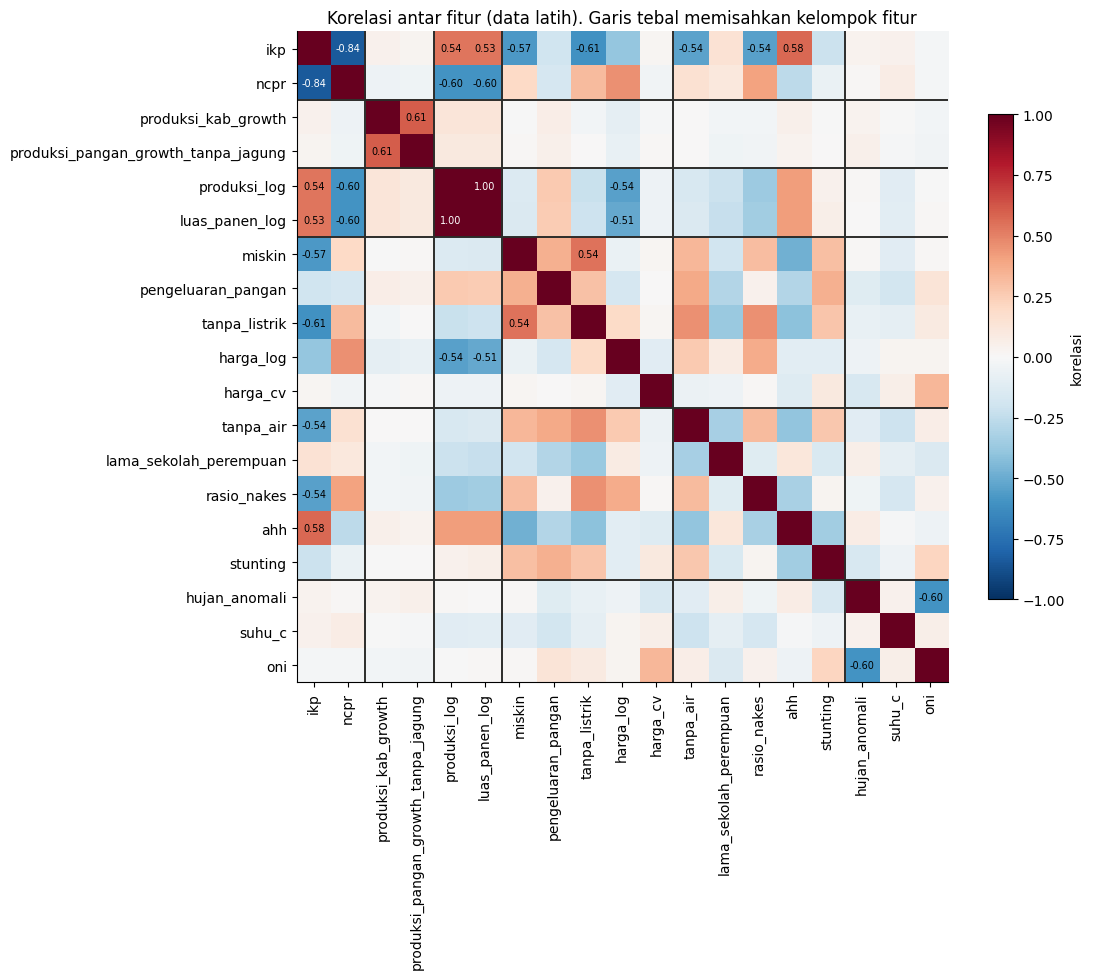

lima pasangan paling mirip:
  produksi_log             x luas_panen_log           0.997
  ikp                      x ncpr                     0.842
  ikp                      x tanpa_listrik            0.608
  produksi_kab_growth      x produksi_pangan_growth_tanpa_jagung 0.606
  hujan_anomali            x oni                      0.600

korelasi tiap fitur dengan target (perubahan log NCPR), diurutkan dari yang terkuat:
produksi_pangan_growth_tanpa_jagung   -0.399
produksi_kab_growth                   -0.381
ncpr                                  -0.168
ikp                                    0.155
oni                                   -0.091
miskin                                -0.075
tanpa_listrik                         -0.061
pengeluaran_pangan                    -0.053
harga_cv                              -0.045
tanpa_air                             -0.037
luas_panen_log                        -0.035
produksi_log                          -0.034
rasio_nakes                        

In [18]:
corr_rows = kab[(kab.tahun <= 2022) & kab.d_ncpr.notna()]
C = corr_rows[NUMERIC].corr()

fig, ax = plt.subplots(figsize=(10.5, 9))
im = ax.imshow(C.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERIC)), NUMERIC, rotation=90)
ax.set_yticks(range(len(NUMERIC)), NUMERIC)
for i in range(len(NUMERIC)):
    for j in range(len(NUMERIC)):
        if i != j and abs(C.values[i, j]) >= 0.5:
            ax.text(j, i, f"{C.values[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(C.values[i, j]) > 0.7 else "black")
for boundary in np.cumsum([len(g) for g in FEATURE_GROUPS.values()])[:-1]:
    ax.axhline(boundary - 0.5, color="#2C2C2A", lw=1.4)
    ax.axvline(boundary - 0.5, color="#2C2C2A", lw=1.4)
ax.grid(False)
ax.set_title("Korelasi antar fitur (data latih). Garis tebal memisahkan kelompok fitur")
fig.colorbar(im, ax=ax, shrink=0.7, label="korelasi")
plt.show()

upper = np.triu(np.ones(C.shape, dtype=bool), 1)
highest = C.abs().where(upper).stack().sort_values(ascending=False)
print("lima pasangan paling mirip:")
for (a, b), v in highest.head(5).items():
    print(f"  {a:24} x {b:24} {v:.3f}")
print("\nkorelasi tiap fitur dengan target (perubahan log NCPR), diurutkan dari yang terkuat:")
print(corr_rows[NUMERIC].corrwith(corr_rows.d_ncpr).sort_values(key=abs, ascending=False).round(3).to_string())

Hasilnya, pasangan fitur paling mirip adalah produksi dan luas panen provinsi (0,997), karena keduanya hampir membawa informasi yang sama. Berikutnya IKP dan NCPR (0,842), karena NCPR adalah salah satu komponen IKP, lalu anomali hujan dan ONI (0,600), karena tahun La Niña cenderung lebih basah. Terhadap target, fitur yang paling kuat hubungannya adalah pertumbuhan produksi pangan (−0,399) dan pertumbuhan produksi padi (−0,381): produksi naik, NCPR turun. NCPR sekarang (−0,168) dan IKP (+0,155) menyusul, sedangkan fitur lain di bawah 0,1. Fitur yang mirip tidak langsung dibuang, karena pilihan fitur diuji langsung dengan model di data validasi.

### Fitur yang Dipakai dan Tidak Dipakai

Dari 36 kolom dataset, 23 kolom diolah menjadi 20 fitur, sedangkan 13 kolom lainnya tidak dijadikan fitur.

**Fitur yang dipakai**, dikelompokkan menurut aspek ketahanan pangan:
- **Riwayat** (`ncpr`, `ikp`): NCPR tahun ini menjadi titik awal, dan model menebak seberapa besar NCPR berubah dari titik itu.
- **Produksi kabupaten** (`produksi_kab_growth`, `produksi_pangan_growth_tanpa_jagung`): dipakai dalam bentuk pertumbuhan, bukan ton, karena yang ditebak adalah perubahan NCPR, sedangkan jumlah ton lebih mencerminkan besar kecilnya kabupaten.
- **Ketersediaan provinsi** (`produksi_log`, `luas_panen_log`): pelengkap ketika data produksi kabupaten bolong, diubah ke logaritma supaya provinsi besar dan kecil sebanding.
- **Keterjangkauan** (`miskin`, `pengeluaran_pangan`, `tanpa_listrik`, `harga_log`, `harga_cv`): kemampuan penduduk memperoleh pangan, termasuk tingkat dan ketidakstabilan harga beras.
- **Pemanfaatan** (`tanpa_air`, `lama_sekolah_perempuan`, `rasio_nakes`, `ahh`, `stunting`): kemampuan penduduk memanfaatkan pangan untuk hidup sehat.
- **Iklim** (`hujan_anomali`, `suhu_c`, `oni`): curah hujan dipakai sebagai anomali terhadap rata-rata kabupaten itu sendiri, karena curah hujan mentah lebih mencerminkan letak geografis.
- **Provinsi** (`prov_kode`): dibaca lewat embedding supaya model bisa mempelajari ciri khas setiap provinsi.

**Kolom yang tidak dipakai**:
- **Identitas** (`kode_bps`, `kab_kota`, `provinsi`, `jenis`, `tahun`): bukan kondisi kabupaten. Kode dan nama bisa membuat model menghafal kabupaten, `provinsi` sudah diwakili `prov_kode`, `jenis` hanya dipakai untuk menyaring kabupaten, dan nilai `tahun` di data uji (2025) dan forecast (2026) tidak pernah dilihat model saat dilatih.
- **FSVA metode baru** (`ncpr_metode_baru` dan empat kolom `*_metode_baru`): hanya ada untuk 2024–2026, sehingga dipakai untuk mengisi `ncpr` dan indikator lama pada tahun-tahun itu, bukan sebagai fitur tersendiri.
- **Jagung** (`produksi_jagung_ton`): datanya kosong mulai 2023, dan satu ton jagung hanya setara sekitar 0,13 ton beras.
- **Produksi padi sebagian tahun** (`produksi_padi_jan_apr_ton`, `produksi_padi_jan_okt_ton`): data Januari–April baru ada mulai 2021, sehingga hanya dipakai saat forecast FSVA 2027 dan simulasi FSVA 2026. Data Januari–Oktober 2026 tidak dipakai karena masih berisi perkiraan BPS.

# Split Train & Test

Data dibagi menurut waktu, bukan acak, supaya model tidak pernah belajar dari masa depan. Model dilatih dengan target FSVA 2020–2025, lalu diuji di **FSVA 2026**, edisi terbaru yang tidak ikut dilatih. FSVA 2025 disisihkan sebentar sebagai validasi untuk memilih fitur dan jumlah epoch, lalu ikut dilatih.

| Bagian | Target | Fitur (baris `tahun`) | Kegunaan |
|---|---|---|---|
| Train | NCPR FSVA 2020–2024 | FSVA 2019–2023 + produksi 2019–2023 | melatih model |
| Validasi (bagian dari train) | NCPR FSVA 2025 (metode baru) | FSVA 2024 + produksi 2024 | memilih fitur dan jumlah epoch, lalu ikut dilatih |
| **Test** | **NCPR FSVA 2026 (metode baru)** | NCPR FSVA 2025 + indikator 2025 (diisi hybrid) + produksi 2025 | evaluasi akhir |
| Forecasting | NCPR FSVA 2027 (kondisi 2026, belum terbit) | NCPR FSVA 2026 + indikator 2026 (diisi hybrid) + produksi padi Januari–April 2026 | ramalan |

Mulai FSVA 2025 metode FSVA berganti. Untuk baris 2024 dan 2025, NCPR sekarang dan NCPR berikutnya sama-sama memakai metode baru (FSVA 2024 hasil hitung ulang, FSVA 2025, FSVA 2026), sehingga perubahan yang ditebak tidak tercampur pergantian metode. Batas atas NCPR metode baru adalah 10 (metode lama 5).

In [19]:
# Baris 2024: NCPR sekarang dan berikutnya memakai metode baru (FSVA 2024 hasil hitung ulang -> FSVA 2025)
new24 = kab.tahun == 2024
kab.loc[new24, "ncpr"] = kab.loc[new24, "ncpr_metode_baru"]
kab.loc[new24, "ncpr_next"] = kab.loc[new24, "ncpr_baru_next"]
kab["d_ncpr"] = np.log1p(kab.ncpr_next) - np.log1p(kab.ncpr)

train = kab[kab.tahun <= 2023]
val = kab[kab.tahun == 2024].dropna(subset=["d_ncpr"])
train_val = pd.concat([train, val])

test = data[(data.tahun == 2025) & data.kode_bps.isin(kab.kode_bps)].dropna(subset=["ncpr_metode_baru", "ncpr_baru_next"]).copy()
test[PROD] = test[PROD].fillna(0)
test = test.assign(ncpr=test.ncpr_metode_baru, ncpr_next=test.ncpr_baru_next)   # titik awal FSVA 2025, jawaban FSVA 2026
test_x = test

for name, part in dict(train=train, validasi=val, test=test).items():
    print(f"{name:10} {len(part):5} baris | baris tahun {part.tahun.min()}-{part.tahun.max()}")

train       2000 baris | baris tahun 2019-2023
validasi     400 baris | baris tahun 2024-2024
test         403 baris | baris tahun 2025-2025


Hasil pembagian data menunjukkan train berisi 2.000 baris (2019–2023), validasi 400 baris (baris 2024: NCPR FSVA 2024 hasil hitung ulang ke FSVA 2025, keduanya metode baru), dan test 403 kabupaten (baris 2025, dengan jawaban NCPR resmi FSVA 2026).

# Modeling

## Metrik Evaluasi

- **MAE** dan **RMSE**: rata-rata kesalahan tebakan dalam satuan NCPR. RMSE lebih menghukum kesalahan yang besar.
- **MASE**: MAE model dibagi MAE tebakan sederhana bahwa NCPR edisi berikutnya sama dengan sekarang. Di bawah 1 berarti model lebih baik daripada menganggap NCPR tidak berubah.
- **Akurasi status defisit**: porsi kabupaten yang status defisitnya (NCPR ≥ 1) tertebak benar.
- **Deteksi perubahan status**: dari kabupaten yang statusnya benar-benar berubah (masuk atau keluar defisit), berapa yang tertebak.
- **Presisi perubahan status**: dari kabupaten yang ditebak berubah status, berapa yang benar.

In [20]:
def metrics(part, pred):
    err = pred - part.ncpr_next.values
    mae_tetap = (part.ncpr - part.ncpr_next).abs().mean()   # MAE tebakan NCPR tidak berubah
    now, actual, guess = part.ncpr.values >= 1, part.ncpr_next.values >= 1, pred >= 1
    changed, flagged, right = now != actual, now != guess, guess == actual
    return {"MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean()), "MASE": np.abs(err).mean() / mae_tetap,
            "akurasi status defisit": right.mean(),
            "deteksi perubahan status": (changed & right).sum() / changed.sum(),
            "presisi perubahan status": (flagged & right).sum() / flagged.sum() if flagged.any() else np.nan}


def level(part, change):
    """Perubahan log hasil model -> NCPR. Batas 0-10 mengikuti FSVA metode baru."""
    return np.clip(np.expm1(np.log1p(part.ncpr.values) + change), 0, 10)

## FT-Transformer

FT-Transformer (Gorishniy dkk., 2021) adalah Transformer untuk data tabel. Setiap fitur numerik diubah menjadi satu token (vektor 32 angka), provinsi menjadi satu token lewat embedding, dan ditambahkan satu token `[CLS]`. Encoder Transformer menghitung attention antartoken, sehingga model bisa mempelajari interaksi antarfitur. Token `[CLS]` di keluaran encoder kemudian dipakai untuk menebak perubahan NCPR.

### Arsitektur

In [21]:
class FTTransformer(nn.Module):
    def __init__(self, n_num, n_prov, d=32, heads=4, layers=2, dropout=0.1):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(n_num, d) * 0.1)   # tiap fitur numerik -> token
        self.bias = nn.Parameter(torch.zeros(n_num, d))
        self.prov = nn.Embedding(n_prov, d)
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        layer = nn.TransformerEncoderLayer(d, heads, 2 * d, dropout, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.out = nn.Linear(d, 1)

    def forward(self, x_num, x_prov):
        tokens = x_num.unsqueeze(-1) * self.weight + self.bias
        tokens = torch.cat([self.cls.expand(len(x_num), -1, -1), tokens, self.prov(x_prov)[:, None]], 1)
        return self.out(self.encoder(tokens)[:, 0]).squeeze(-1)

### Scaling dan Training

Fitur numerik distandardisasi dengan rata-rata dan simpangan baku dari baris yang dipakai melatih model, bukan dari data validasi atau test. Model dilatih dengan loss L1 (karena metrik utamanya MAE) dan optimizer AdamW, batch 64. Pelatihan dilakukan dua tahap:

1. Latih dengan train, pantau MAE NCPR di validasi setiap epoch, dan berhenti kalau 40 epoch berturut-turut tidak membaik (early stopping). Epoch dengan MAE validasi terkecil dicatat.
2. Latih ulang dari awal dengan train + validasi selama jumlah epoch terbaik itu, supaya data FSVA 2025 ikut dipelajari.

In [22]:
def numeric(features):
    return [f for f in features if f != "prov_kode"]


def to_tensor(model, part):
    return (torch.tensor(model.scaler.transform(part[model.cols]), dtype=torch.float32),
            torch.tensor(part.prov_kode.values))


def predict_ft(model, part):
    """Perkiraan perubahan log NCPR."""
    model.eval()
    with torch.no_grad():
        return model(*to_tensor(model, part)).numpy()


def fit_ft(fit_rows, val_rows, features, epochs=None, seed=SEED, max_epochs=400, patience=40):
    """Latih FT-Transformer dengan fit_rows; scaler dipelajari dari fit_rows saja.
    Tanpa `epochs`: early stopping memakai MAE NCPR di val_rows, lalu bobot terbaik dikembalikan."""
    torch.manual_seed(seed)
    model = FTTransformer(len(numeric(features)), len(PROVINCES))
    model.cols, model.scaler = numeric(features), StandardScaler().fit(fit_rows[numeric(features)])
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    x, p = to_tensor(model, fit_rows)
    y = torch.tensor(fit_rows.d_ncpr.values, dtype=torch.float32)
    history, best = [], None
    for epoch in range(1, (epochs or max_epochs) + 1):
        model.train()
        for i in torch.randperm(len(x)).split(64):
            opt.zero_grad()
            nn.functional.l1_loss(model(x[i], p[i]), y[i]).backward()
            opt.step()
        if epochs:
            continue
        history.append(np.abs(level(val_rows, predict_ft(model, val_rows)) - val_rows.ncpr_next.values).mean())
        if history[-1] == min(history):
            best = {k: v.clone() for k, v in model.state_dict().items()}
        elif epoch - int(np.argmin(history)) - 1 >= patience:
            break
    if best:
        model.load_state_dict(best)
    model.eval()
    return model, history


def ft_two_stage(fit_rows, val_rows, final_rows, features, seed=SEED):
    """Tahap 1: pilih jumlah epoch dengan early stopping. Tahap 2: latih ulang dengan final_rows."""
    _, history = fit_ft(fit_rows, val_rows, features, seed=seed)
    model, _ = fit_ft(final_rows, None, features, epochs=int(np.argmin(history)) + 1, seed=seed)
    return model, history


x_check = StandardScaler().fit_transform(train[numeric(FEATURES)])
print(f"contoh scaling 19 fitur numerik di train: rata {x_check.mean():+.3f}, baku {x_check.std():.3f}")

contoh scaling 19 fitur numerik di train: rata -0.000, baku 1.000


Hasilnya, setelah standardisasi, fitur numerik di data train punya rata-rata 0 dan simpangan baku 1. Di dalam `fit_ft`, scaler selalu dipelajari ulang dari baris yang sedang dipakai melatih model, sehingga data validasi dan test tidak ikut menentukan skalanya.

### Model Utama: 20 Fitur

parameter: 19,457 | berhenti di epoch 63, terbaik epoch 23, MAE validasi 0.247 | 59 detik


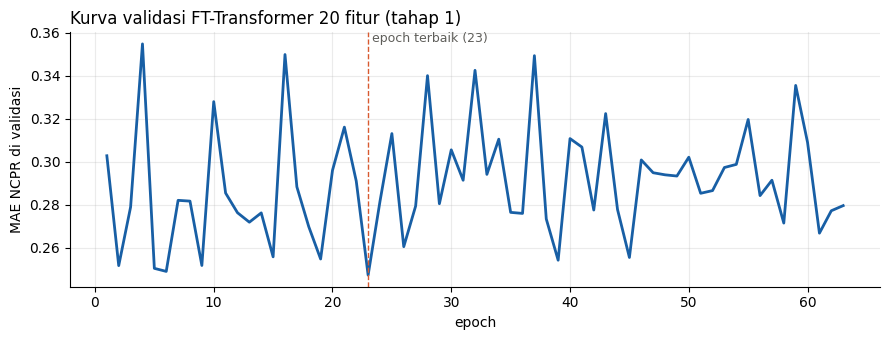

MAE                         0.338
RMSE                        0.885
MASE                        0.820
akurasi status defisit      0.983
deteksi perubahan status    0.760
presisi perubahan status    0.950
dtype: float64

In [23]:
FEATURES_FT = FEATURES
assert test_x[FEATURES_FT].notna().all().all(), "masih ada fitur kosong di data test"

t0 = time.time()
ft, history = ft_two_stage(train, val, train_val, FEATURES_FT)
BEST_EPOCH = int(np.argmin(history)) + 1
print(f"parameter: {sum(p.numel() for p in ft.parameters()):,} | berhenti di epoch {len(history)}, "
      f"terbaik epoch {BEST_EPOCH}, MAE validasi {min(history):.3f} | {time.time() - t0:.0f} detik")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(range(1, len(history) + 1), history, color=COLORS["utama"], lw=2)
ax.axvline(BEST_EPOCH, color=COLORS["oranye"], ls="--", lw=1)
ax.text(BEST_EPOCH, ax.get_ylim()[1], f" epoch terbaik ({BEST_EPOCH})", va="top", fontsize=9, color="#5F5E5A")
ax.set_xlabel("epoch"); ax.set_ylabel("MAE NCPR di validasi")
ax.set_title("Kurva validasi FT-Transformer 20 fitur (tahap 1)", loc="left")
plt.tight_layout(); plt.show()

PRED = {"FT-Transformer 20 fitur": level(test, predict_ft(ft, test_x))}
pd.Series(metrics(test, PRED["FT-Transformer 20 fitur"])).round(3)

Kurva menunjukkan MAE validasi (FSVA 2025) per epoch; garis putus-putus menandai epoch terbaik. Epoch terbaik adalah epoch 23 (MAE validasi 0,247); setelah itu MAE validasi tidak membaik selama 40 epoch, sehingga pelatihan berhenti di epoch 63. Di data uji FSVA 2026, model satu seed ini memperoleh MASE 0,820 dan akurasi status defisit 98,3%. Model menebak benar 19 dari 25 kabupaten yang berubah status (deteksi 76%), dan 19 dari 20 kabupaten yang ditebak berubah memang benar (presisi 95%).

### Kestabilan Antar-Seed

Transformer yang dilatih dari nol dengan data kecil bisa memberi hasil berbeda hanya karena bobot awal dan urutan batch yang berbeda (diatur oleh *seed*). Model utama dilatih ulang dengan 5 seed, dan tebakan kelima model dirata-rata (ensemble) supaya hasilnya lebih stabil.

In [24]:
SEEDS = [0, 1, 2, 3, 4]


def ensemble(features):
    """Latih model dengan 5 seed; kembalikan kelima model dan MASE test tiap seed."""
    models = [ft_two_stage(train, val, train_val, features, seed=seed)[0] for seed in SEEDS]
    mase = [metrics(test, level(test, predict_ft(m, test_x)))["MASE"] for m in models]
    return models, mase


ft_models, mase_seed = ensemble(FEATURES_FT)
MAIN = "FT-Transformer 20 fitur (rata-rata 5 seed)"
PRED[MAIN] = np.mean([level(test, predict_ft(m, test_x)) for m in ft_models], axis=0)
print(f"MASE antar-seed: {min(mase_seed):.3f}-{max(mase_seed):.3f} | "
      f"rata-rata 5 seed (ensemble): {metrics(test, PRED[MAIN])['MASE']:.3f}")

MASE antar-seed: 0.798-0.882 | rata-rata 5 seed (ensemble): 0.840


Hasil satu kali pelatihan berubah cukup besar hanya karena seed: MASE kelima seed berkisar 0,798–0,882. Model seed 42 di atas (MASE 0,820) hanyalah salah satu kemungkinan hasil, sehingga hasil satu seed tidak bisa dijadikan pegangan. Karena itu hasil model utama dilaporkan sebagai rata-rata tebakan 5 seed (MASE 0,840).

## Skenario: Seleksi Fitur

Setiap set fitur dilatih dengan train dan dinilai di validasi (FSVA 2025): semua 20 fitur, 20 fitur dikurangi satu kelompok, dan set ringkas 4 fitur yang hanya berisi pendorong langsung NCPR (NCPR sekarang, pertumbuhan produksi padi dan pangan, provinsi). Data test tidak dipakai di tahap ini.

In [25]:
RINGKAS = ["ncpr", *PROD, "prov_kode"]
FEATURE_SETS = {"lengkap (20 fitur)": FEATURES}
FEATURE_SETS |= {f"tanpa {group}": [f for f in FEATURES if f not in cols] for group, cols in FEATURE_GROUPS.items()}
FEATURE_SETS["ringkas: NCPR + produksi + provinsi"] = RINGKAS

t0 = time.time()
selection = {}
for name, features in FEATURE_SETS.items():
    model, history = fit_ft(train, val, features)
    selection[name] = {**metrics(val, level(val, predict_ft(model, val))), "epoch terbaik": int(np.argmin(history)) + 1}
selection = pd.DataFrame(selection).T

print(f"{time.time() - t0:.0f} detik | MAE validasi terkecil: {selection.MAE.idxmin()}")
selection[["MAE", "MASE", "akurasi status defisit", "deteksi perubahan status", "presisi perubahan status", "epoch terbaik"]].round(3)

252 detik | MAE validasi terkecil: ringkas: NCPR + produksi + provinsi


,MAE,MASE,akurasi status defisit,deteksi perubahan status,presisi perubahan status,epoch terbaik
lengkap (20 fitur),0.247,0.932,0.945,0.304,0.538,23.0
tanpa riwayat,0.215,0.809,0.952,0.304,0.700,22.0
tanpa produksi kab,0.260,0.981,0.955,0.217,1.000,8.0
tanpa ketersediaan provinsi,0.248,0.936,0.952,0.348,0.667,3.0
tanpa keterjangkauan,0.239,0.899,0.945,0.217,0.556,27.0
tanpa pemanfaatan,0.240,0.905,0.955,0.304,0.778,14.0
tanpa iklim,0.225,0.846,0.960,0.522,0.706,27.0
ringkas: NCPR + produksi + provinsi,0.214,0.805,0.960,0.391,0.818,29.0


Hasilnya, set ringkas 4 fitur memberi MASE validasi terbaik (0,805), sedangkan 20 fitur 0,932. Membuang kelompok riwayat, keterjangkauan, pemanfaatan, atau iklim dari 20 fitur justru memperbaiki hasil (0,809–0,905), dan membuang ketersediaan provinsi hampir tidak berpengaruh (0,936). Sebaliknya, tanpa produksi kabupaten MASE naik menjadi 0,981, hampir sama dengan menganggap NCPR tidak berubah. Jadi produksi kabupaten adalah satu-satunya kelompok yang jelas penting; kelompok lain lebih banyak menambah gangguan.

## Skenario: 4 Fitur

Set ringkas 4 fitur dilatih dengan cara yang sama (5 seed, dirata-rata), lalu dibandingkan dengan model utama di data test FSVA 2026.

In [26]:
models_4, _ = ensemble(RINGKAS)
PRED["Skenario 4 fitur (rata-rata 5 seed)"] = np.mean([level(test, predict_ft(m, test_x)) for m in models_4], axis=0)
pd.DataFrame({name: metrics(test, pred) for name, pred in PRED.items()}).T.round(3)

,MAE,RMSE,MASE,akurasi status defisit,deteksi perubahan status,presisi perubahan status
FT-Transformer 20 fitur,0.338,0.885,0.820,0.983,0.76,0.950
FT-Transformer 20 fitur (rata-rata 5 seed),0.346,0.891,0.840,0.975,0.64,0.941
Skenario 4 fitur (rata-rata 5 seed),0.316,0.855,0.768,0.980,0.88,0.815


Hasilnya, skenario 4 fitur lebih baik dari model utama di data uji dengan produksi setahun penuh: MASE 0,768 dibanding 0,840, akurasi status defisit 98,0% dibanding 97,5%, dan menangkap 22 dari 25 kabupaten yang berubah status (deteksi 88%) dibanding 16 (64%). Presisinya lebih rendah (81,5% dibanding 94,1%), karena skenario 4 fitur lebih berani menebak perubahan. Keunggulan ini tidak berlaku saat produksi hanya tersedia untuk Januari–April, seperti dibahas di bagian ekspor.

# Evaluation

## Tabel Metrik

In [27]:
table = pd.DataFrame({name: metrics(test, pred) for name, pred in PRED.items()}).T
print(f"test: NCPR FSVA 2026 metode baru, {len(test)} kabupaten | "
      f"status berubah 2025 -> 2026: {int(((test.ncpr >= 1) != (test.ncpr_next >= 1)).sum())} kabupaten")
table.round(3)

test: NCPR FSVA 2026 metode baru, 403 kabupaten | status berubah 2025 -> 2026: 25 kabupaten


,MAE,RMSE,MASE,akurasi status defisit,deteksi perubahan status,presisi perubahan status
FT-Transformer 20 fitur,0.338,0.885,0.820,0.983,0.76,0.950
FT-Transformer 20 fitur (rata-rata 5 seed),0.346,0.891,0.840,0.975,0.64,0.941
Skenario 4 fitur (rata-rata 5 seed),0.316,0.855,0.768,0.980,0.88,0.815


Model utama 20 fitur (rata-rata 5 seed) memperoleh MASE 0,840, artinya kesalahan tebakannya 16% lebih kecil daripada menganggap NCPR tidak berubah. Skenario 4 fitur memperoleh MASE 0,768, atau kesalahan tebakannya 23% lebih kecil. Kedua model juga lebih tepat menebak status defisit daripada baseline persistensi (97,5% dan 98,0%, dibanding 93,8%).

## Forecast NCPR FSVA 2027 (Kondisi 2026)

FSVA 2027 memotret kondisi tahun 2026, yang belum selesai, sehingga produksi 2026 setahun penuh belum ada. Karena itu pertumbuhan produksi setahun diganti dengan pertumbuhan produksi padi Januari–April 2026 dibanding Januari–April 2025, yaitu bulan-bulan yang sudah terealisasi. Titik awal forecast adalah NCPR resmi FSVA 2026.

Grafik menampilkan kabupaten yang diramal berubah status: titik abu-abu adalah NCPR FSVA 2026, dan titik berwarna adalah forecast FSVA 2027 (oranye = masuk defisit, hijau = keluar dari defisit). Tanda * menandai kabupaten yang produksi padi Januari–April 2026-nya berubah lebih dari 2,7 kali dibanding 2025.

403 kabupaten | porsi defisit: FSVA 2026 44.4% -> forecast 2027 46.2% | berubah status: 11 (masuk 9, keluar 2)


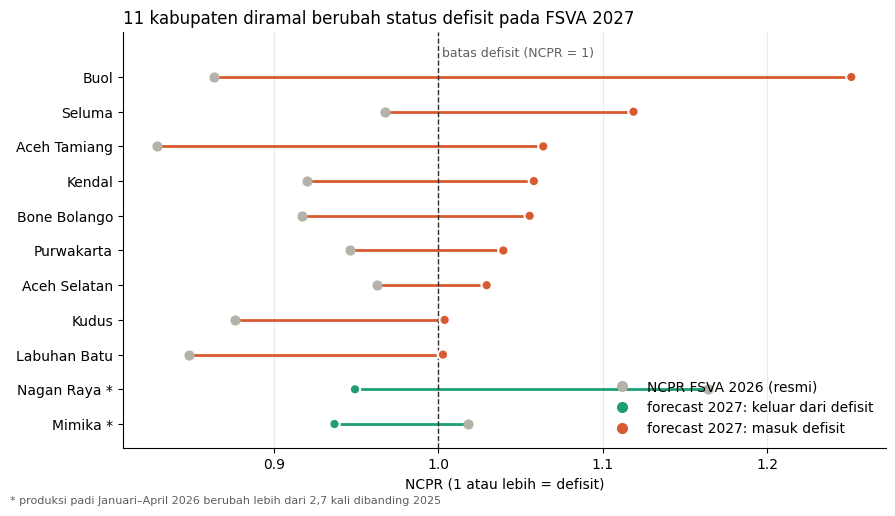

In [28]:
predict_ncpr = lambda rows: np.mean([level(rows, predict_ft(m, rows)) for m in ft_models], axis=0)


def with_partial_growth(rows, column="produksi_padi_jan_apr_ton"):
    """Ganti pertumbuhan produksi setahun dengan pertumbuhan produksi padi Januari-April (tahun ini dibanding tahun lalu)."""
    by_year = data.set_index(["kode_bps", "tahun"])[column]
    now = by_year.reindex(pd.MultiIndex.from_arrays([rows.kode_bps, rows.tahun])).values
    prev = by_year.reindex(pd.MultiIndex.from_arrays([rows.kode_bps, rows.tahun - 1])).values
    growth = np.nan_to_num(np.clip(np.log(now / prev), -1.5, 1.5), nan=0.0)   # kosong = dianggap tidak berubah
    return rows.assign(produksi_kab_growth=growth, produksi_pangan_growth_tanpa_jagung=growth)

fc = data[(data.tahun == 2026) & data.kode_bps.isin(kab.kode_bps) & data.ncpr_metode_baru.notna()].copy()
fc = fc.assign(ncpr=fc.ncpr_metode_baru)
fc_x = with_partial_growth(fc)
forecast = fc[["kode_bps", "kab_kota", "provinsi", "ncpr"]].rename(columns={"ncpr": "ncpr_2026"})
forecast["ncpr_2027"] = predict_ncpr(fc_x)
forecast["cek_data_produksi"] = fc_x.produksi_kab_growth.abs().values >= 1

now, nxt = forecast.ncpr_2026 >= 1, forecast.ncpr_2027 >= 1
print(f"{len(forecast)} kabupaten | porsi defisit: FSVA 2026 {now.mean():.1%} -> forecast 2027 {nxt.mean():.1%} | "
      f"berubah status: {(now != nxt).sum()} (masuk {(~now & nxt).sum()}, keluar {(now & ~nxt).sum()})")

order = forecast[now != nxt].assign(masuk=~now[now != nxt]).sort_values(["masuk", "ncpr_2027"])
y = np.arange(len(order))
colors = np.where(order.masuk, COLORS["oranye"], COLORS["hijau"])
fig, ax = plt.subplots(figsize=(9, 0.32 * len(order) + 1.6))
ax.hlines(y, order.ncpr_2026, order.ncpr_2027, color=colors, lw=2)
ax.scatter(order.ncpr_2026, y, s=40, color=COLORS["abu"], zorder=3)
ax.scatter(order.ncpr_2027, y, s=55, color=colors, edgecolor="white", linewidth=1.5, zorder=4)
ax.axvline(1, color="#2C2C2A", ls="--", lw=1)
ax.text(1, len(order) - 0.4, " batas defisit (NCPR = 1)", fontsize=9, color="#5F5E5A")
ax.set_yticks(y, order.kab_kota + np.where(order.cek_data_produksi, " *", ""))
ax.set_ylim(-0.7, len(order) + 0.3)
ax.grid(axis="y", visible=False)
ax.set_xlabel("NCPR (1 atau lebih = defisit)")
ax.set_title(f"{len(order)} kabupaten diramal berubah status defisit pada FSVA 2027", loc="left")
dot = lambda color, label: Line2D([], [], marker="o", ls="", markersize=7, color=color, label=label)
ax.legend(handles=[dot(COLORS["abu"], "NCPR FSVA 2026 (resmi)"),
                   dot(COLORS["hijau"], "forecast 2027: keluar dari defisit"),
                   dot(COLORS["oranye"], "forecast 2027: masuk defisit")], loc="lower right", frameon=False)
fig.text(0.01, 0.005, "* produksi padi Januari–April 2026 berubah lebih dari 2,7 kali dibanding 2025", fontsize=8, color="#5F5E5A")
plt.tight_layout(); plt.show()

Hasilnya, porsi kabupaten defisit diramal naik dari 44,4% (FSVA 2026) menjadi 46,2% pada FSVA 2027. Sebanyak 11 kabupaten diramal berubah status: 9 masuk defisit (Aceh Selatan, Aceh Tamiang, Labuhan Batu, Seluma, Purwakarta, Kudus, Kendal, Buol, dan Bone Bolango) dan 2 keluar (Nagan Raya dan Mimika). Hampir semua ramalan berada dekat batas defisit (NCPR sekitar 0,94–1,12), kecuali Buol (1,25), jadi perubahan statusnya tipis dan bisa berbalik kalau produksi Mei–Desember 2026 berbeda dari perkiraan. Nagan Raya dan Mimika bertanda * karena produksi padi Januari–April 2026-nya berubah sangat besar, jadi ramalannya perlu dibaca hati-hati. Forecast ini sebaiknya diperbarui dengan nowcasting begitu produksi 2026 setahun penuh dirilis.

# Save Model

Bobot kelima FT-Transformer untuk kedua skenario (20 fitur dan 4 fitur), beserta scaler, daftar fitur, dan daftar provinsinya, disimpan di folder `hasil/`. Dengan bobot ini, ramalan dan simulasi bisa dihitung ulang tanpa melatih ulang, sehingga angkanya tidak berubah.

In [29]:
OUT = Path("hasil")
OUT.mkdir(exist_ok=True)
for nama, models, features in [("20fitur", ft_models, FEATURES_FT), ("4fitur", models_4, RINGKAS)]:
    torch.save({"state_dicts": [m.state_dict() for m in models], "seeds": SEEDS, "features": features,
                "scalers": [(m.scaler.mean_, m.scaler.scale_) for m in models], "provinces": PROVINCES},
               OUT / f"ft_ncpr_{nama}_5seed.pt")
print("tersimpan:", sorted(p.name for p in OUT.iterdir()))

tersimpan: ['ft_ncpr_20fitur_5seed.pt', 'ft_ncpr_4fitur_5seed.pt']


## Ekspor Hasil untuk Website (`ncpr_2027.json`)

Hasil forecast disimpan ke `ncpr_2027.json`, yang dibaca langsung oleh website PANGNUSA tanpa backend. File berisi semua kabupaten: NCPR resmi FSVA 2024–2026, ramalan FSVA 2027 beserta kelas dan perubahan statusnya untuk kabupaten yang diramal, dan alasan untuk kabupaten yang tidak diramal. Ada dua skenario: **20 fitur sebagai skenario utama** dan 4 fitur sebagai pembanding.

Kinerja setiap skenario di data uji FSVA 2026 dihitung dua kali: dengan produksi setahun penuh, dan dengan produksi padi Januari–April saja. Perhitungan kedua sekaligus menjadi **simulasi FSVA 2026** (`simulasi_2026` di JSON): model meramal FSVA 2026 dari posisi pertengahan 2025, yaitu dari NCPR FSVA 2025 dan produksi padi Januari–April 2025, lalu ramalannya dicocokkan dengan FSVA 2026 resmi. Simulasi ini memakai kondisi yang sama seperti saat meramal FSVA 2027, dan sah karena FSVA 2026 tidak pernah dipakai untuk melatih model.

In [30]:
SKENARIO = {"4_fitur": ("FT-Transformer 4 fitur (rata-rata 5 seed)", models_4),
            "20_fitur": ("FT-Transformer 20 fitur (rata-rata 5 seed)", ft_models)}
UTAMA = "20_fitur"
ensemble_ncpr = lambda models, rows: np.mean([level(rows, predict_ft(m, rows)) for m in models], axis=0)
kelas = lambda v: 6 - int(np.digitize(v, [0.5, 0.75, 1, 1.25, 1.5]))   # 1-3 defisit, 4-6 surplus (Tabel 2.2 FSVA 2025)
STATUS = {(False, True): "masuk_defisit", (True, False): "keluar_defisit",
          (True, True): "tetap_defisit", (False, False): "tetap_surplus"}


def kinerja(part, pred):
    now, actual, guess = part.ncpr.values >= 1, part.ncpr_next.values >= 1, pred >= 1
    changed, flagged, right = now != actual, now != guess, guess == actual
    m = metrics(part, pred)
    return {"diuji_pada": "FSVA 2026", "akurasi_status_persen": round(100 * right.mean(), 1),
            "akurasi_status_jika_tidak_berubah_persen": round(100 * (~changed).mean(), 1),
            "perubahan_status_sebenarnya": int(changed.sum()), "perubahan_status_tertangkap": int((changed & right).sum()),
            "peringatan_dikeluarkan": int(flagged.sum()), "peringatan_benar": int((flagged & right).sum()),
            "mase": round(m["MASE"], 3), "mae": round(m["MAE"], 3), "rmse": round(m["RMSE"], 3)}


kabupaten = data[data.jenis == "Kabupaten"].drop_duplicates("kode_bps")
resmi = data[data.tahun.between(2024, 2026)].pivot(index="kode_bps", columns="tahun", values="ncpr_metode_baru")
awal = fc.ncpr.values >= 1
test_jan_apr = with_partial_growth(test)   # uji dengan kondisi yang sama seperti saat meramal FSVA 2027

ramalan, simulasi, meta_skenario = {}, {}, {}
for key, (nama_model, models) in SKENARIO.items():
    # dibulatkan dulu, supaya kelas dan status dihitung dari angka yang sama dengan yang tertulis di JSON
    ramalan[key] = pd.Series(ensemble_ncpr(models, fc_x), index=fc.kode_bps.values).round(4)
    simulasi[key] = pd.Series(ensemble_ncpr(models, test_jan_apr), index=test.kode_bps.values).round(4)   # ramalan FSVA 2026
    akhir = ramalan[key].values >= 1
    meta_skenario[key] = {
        "model": nama_model,
        "kinerja": kinerja(test, ensemble_ncpr(models, test_x)),
        "kinerja_jan_apr": kinerja(test, simulasi[key].values),
        "ringkasan": {"total_wilayah": len(kabupaten), "diramal": len(fc), "tidak_diramal": len(kabupaten) - len(fc),
                      "masuk_defisit": int((~awal & akhir).sum()), "keluar_defisit": int((awal & ~akhir).sum()),
                      "persen_defisit_resmi": round(100 * awal.mean(), 1), "persen_defisit_ramalan": round(100 * akhir.mean(), 1)}}

cek = pd.Series(fc_x.produksi_kab_growth.abs().values >= 1, index=fc.kode_bps.values)
ncpr_2025 = pd.Series(test.ncpr.values, index=test.kode_bps.values)
rows = []
for k in kabupaten.itertuples():
    ncpr_2026 = resmi.loc[k.kode_bps, 2026]
    diramal = k.kode_bps in ramalan[UTAMA].index
    skenario = {key: {"ncpr_ramalan": round(float(r[k.kode_bps]), 4), "kelas_ramalan": kelas(r[k.kode_bps]),
                      "perubahan_status": STATUS[(ncpr_2026 >= 1, r[k.kode_bps] >= 1)]}
                for key, r in ramalan.items()} if diramal else None
    # Simulasi: ramalan FSVA 2026 dari posisi pertengahan 2025, dibandingkan dengan FSVA 2026 resmi
    simulasi_2026 = {"status_sebenarnya": STATUS[(ncpr_2025[k.kode_bps] >= 1, ncpr_2026 >= 1)],
                     **{key: {"ncpr_ramalan": round(float(s[k.kode_bps]), 4),
                              "perubahan_status": STATUS[(ncpr_2025[k.kode_bps] >= 1, s[k.kode_bps] >= 1)]}
                        for key, s in simulasi.items()}} if k.kode_bps in ncpr_2025.index else None
    rows.append({"kode_bps": int(k.kode_bps), "nama": k.kab_kota.replace("Kota Baru", "Kotabaru"),
                 "provinsi": k.provinsi, "jenis": "Kabupaten", "diramal": diramal,
                 "alasan": None if diramal else "data_produksi_tidak_ada",
                 "ncpr_resmi": {f"FSVA {t}": None if pd.isna(v) else round(float(v), 4) for t, v in resmi.loc[k.kode_bps].items()},
                 **(skenario[UTAMA] if diramal else {"ncpr_ramalan": None, "kelas_ramalan": None, "perubahan_status": None}),
                 "kelas_awal": None if pd.isna(ncpr_2026) else kelas(ncpr_2026),
                 "cek_data_produksi": bool(cek.get(k.kode_bps, False)),
                 "skenario": skenario, "simulasi_2026": simulasi_2026})

utama = meta_skenario[UTAMA]
meta = {"dibuat": pd.Timestamp.now().strftime("%Y-%m-%d"), "edisi_awal": "FSVA 2026", "kondisi_awal": 2025,
        "edisi_ramalan": "FSVA 2027", "kondisi_ramalan": 2026, "data_produksi_sampai": "2026-04",
        "model": utama["model"], "kinerja": utama["kinerja"], "kinerja_jan_apr": utama["kinerja_jan_apr"],
        "ringkasan": utama["ringkasan"], "skenario_utama": UTAMA, "skenario": meta_skenario,
        "simulasi_2026": {"edisi_awal": "FSVA 2025", "edisi_ramalan": "FSVA 2026", "data_produksi_sampai": "2025-04",
                          "keterangan": "Ramalan FSVA 2026 dari posisi pertengahan 2025, dibandingkan dengan FSVA 2026 resmi. "
                                        "Kinerjanya ada di kinerja_jan_apr setiap skenario."},
        "sumber_data": "dataset_gabungan_kabupaten.csv, notebook Kelompok_6_FT_Transformer_v2.ipynb"}

Path("ncpr_2027.json").write_text(json.dumps({"meta": meta, "kabupaten": rows}, ensure_ascii=False, indent=1), encoding="utf-8")
print(f"ncpr_2027.json: {len(rows)} kabupaten, {sum(r['diramal'] for r in rows)} diramal")
pd.DataFrame({key: {**s["ringkasan"], **{f"uji {k}": v for k, v in s["kinerja"].items() if k != "diuji_pada"},
                    **{f"uji jan-apr {k}": v for k, v in s["kinerja_jan_apr"].items() if k != "diuji_pada"}}
              for key, s in meta_skenario.items()})

ncpr_2027.json: 416 kabupaten, 403 diramal


,4_fitur,20_fitur
total_wilayah,416.000,416.000
diramal,403.000,403.000
tidak_diramal,13.000,13.000
masuk_defisit,14.000,9.000
keluar_defisit,9.000,2.000
persen_defisit_resmi,44.400,44.400
persen_defisit_ramalan,45.700,46.200
uji akurasi_status_persen,98.000,97.500
uji akurasi_status_jika_tidak_berubah_persen,93.800,93.800
uji perubahan_status_sebenarnya,25.000,25.000


Hasilnya, skenario 4 fitur unggul ketika produksi setahun penuh tersedia (MASE 0,768 dibanding 0,840), tetapi dalam simulasi dengan produksi Januari–April, skenario 20 fitur lebih tepat: MASE 0,907 dibanding 0,945, akurasi status defisit 97,0% dibanding 94,5% (baseline persistensi 93,8%), dan 14 dari 15 peringatannya benar, sedangkan skenario 4 fitur hanya 18 dari 33. Skenario 4 fitur memang menangkap lebih banyak perubahan status (18 dibanding 14 dari 25), tetapi dengan 15 alarm palsu, karena model ini hanya bergantung pada produksi dan terlalu peka terhadap naik-turun produksi Januari–April akibat pergeseran waktu tanam dan panen. Pola yang sama muncul pada tiga kali pelatihan di mesin yang berbeda. Karena ramalan FSVA 2027 dibuat dengan produksi Januari–April, skenario 20 fitur dipakai sebagai skenario utama; skenario 4 fitur lebih cocok dipakai begitu produksi 2026 setahun penuh dirilis.

Pada skenario utama, ramalan FSVA 2027 menghasilkan 9 kabupaten masuk defisit dan 2 keluar, sedangkan skenario 4 fitur menghasilkan 14 masuk dan 9 keluar.

# Kesimpulan

- Model utama adalah FT-Transformer dengan 20 fitur, dilatih sampai FSVA 2025 dan diuji di FSVA 2026 pada 403 kabupaten. Indikator FSVA lama untuk 2025–2026 diisi secara hybrid: empat indikator dari FSVA metode baru (definisinya sama, dicek di 2024) dan sisanya dari nilai terakhir.
- Dengan produksi setahun penuh, model utama memperoleh MASE 0,840 (rata-rata 5 seed), akurasi status defisit 97,5%, dan menangkap 16 dari 25 perubahan status, lebih baik daripada menganggap NCPR tidak berubah (akurasi 93,8%). Skenario 4 fitur lebih baik dalam kondisi ini: MASE 0,768 dan 22 dari 25 perubahan status tertebak. Seleksi fitur menunjukkan hanya produksi kabupaten yang jelas penting.
- Dalam simulasi FSVA 2026 dengan produksi Januari–April, kondisi yang sama seperti saat meramal FSVA 2027, model utama lebih tepat: MASE 0,907, akurasi 97,0%, dan 14 dari 15 peringatan benar, sedangkan skenario 4 fitur memberi 15 alarm palsu. Karena itu 20 fitur dipakai sebagai skenario utama untuk ramalan FSVA 2027.
- Hasil FT-Transformer berubah antar-seed (MASE 0,798–0,882), sehingga dilaporkan sebagai rata-rata 5 seed. Pelatihan di mesin yang sama selalu memberi hasil yang sama persis, tetapi di mesin lain (misalnya Colab) angkanya bisa sedikit berbeda. Bobot model disimpan supaya ramalan bisa dihitung ulang tanpa melatih ulang.
- Forecasting FSVA 2027 (kondisi 2026) memakai produksi padi Januari–April 2026 yang sudah terealisasi. Porsi kabupaten defisit diramal naik dari 44,4% menjadi 46,2%, dengan 11 kabupaten berubah status (9 masuk defisit, 2 keluar).
- Keterbatasan: lima indikator FSVA lama diisi nilai 2024, sehingga untuk 2026 nilainya berumur dua tahun; pisang dan jagung tidak tersedia per kabupaten; data bulanan hanya ada untuk padi; 13 kabupaten tanpa catatan produksi (12 di Papua dan Kepulauan Seribu) serta 98 kota tidak diramal; dan pengujian hanya dilakukan pada satu edisi FSVA dengan 25 perubahan status.